In [105]:
import torch
from torch import nn
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torch_directml

In [106]:
BATCH_SIZE = 128
DEVICE = torch_directml.device(0)
LEARNING_RATE = 1e-3
EPOCHS = 10
NOISE_FACTOR = 0.25

In [107]:
def strict_size_collate(batch):
    valid_batch = [
        item for item in batch 
        if item is not None and item[0].shape == torch.Size([3, 150, 150])
    ]
    
    if len(valid_batch) == 0:
        return None
        
    return torch.utils.data.dataloader.default_collate(valid_batch)

In [108]:
train_data = ImageFolder(root="data/intel-image/train", transform=transforms.ToTensor())
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, pin_memory=False, num_workers=0, collate_fn=strict_size_collate)

test_data = ImageFolder(root="data/intel-image/test", transform=transforms.ToTensor())
test_dataloader = DataLoader(test_data, batch_size=len(train_data.classes), shuffle=False, pin_memory=False, num_workers=0, collate_fn=strict_size_collate)

In [109]:
train_data[0][0].shape

torch.Size([3, 150, 150])

In [110]:
train_data.class_to_idx

{'buildings': 0,
 'forest': 1,
 'glacier': 2,
 'mountain': 3,
 'sea': 4,
 'street': 5}

In [111]:
class AutoencoderWithUNET(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder 
        #   block1  [3, 150, 150] -> [16, 75, 75]
        self.encoder_block1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=(3, 3), stride=2, padding=1),
            nn.BatchNorm2d(num_features=16),
            nn.ReLU(inplace=True),
        )
        #   block2  [16, 75, 75] -> [64, 38, 38]
        self.encoder_block2 = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=64, kernel_size=(3, 3), stride=2, padding=1),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(inplace=True)
        )
        #   block3  [64, 38, 38] -> [128, 19, 19]
        self.encoder_block3 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=(3, 3), stride=2, padding=1),
            nn.BatchNorm2d(num_features=128),
            nn.ReLU(inplace=True)
        )

        # Bottleneck    [256, 19, 19] -> [256, 10, 10]
        self.bottleneck = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=(3, 3), stride=2, padding=1),
            nn.BatchNorm2d(num_features=256),
            nn.ReLU(inplace=True)
        )

        # Decoder
        #   block1  [256, 10, 10] -> [128, 19, 19]
        self.up1 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=(3, 3), stride=2, padding=1, output_padding=0)

        self.decoder_block1 = nn.Sequential(
            nn.Conv2d(in_channels=256, out_channels=128, kernel_size=(3, 3), stride=1, padding=1),
            nn.BatchNorm2d(num_features=128),
            nn.ReLU(inplace=True)
        )

        #   block2  [128, 19, 19] -> [64, 38, 38]
        self.up2 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=(3, 3), stride=2, padding=1, output_padding=1)

        self.decoder_block2 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=64, kernel_size=(3, 3), stride=1, padding=1),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(inplace=True)
        )

        #   block3  [64, 38, 38] -> [16, 75, 75]
        self.up3 = nn.ConvTranspose2d(in_channels=64, out_channels=16, kernel_size=(3, 3), stride=2, padding=1, output_padding=0)

        self.decoder_block3 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=16, kernel_size=(3, 3), stride=1, padding=1),
            nn.BatchNorm2d(num_features=16),
            nn.ReLU(inplace=True)
        )

        #   block4  [16, 75, 75] -> [3, 150, 150]
        self.final_up = nn.ConvTranspose2d(in_channels=16, out_channels=3, kernel_size=(3, 3), stride=2, padding=1, output_padding=1)
        self.final_act = nn.Sigmoid()

    def forward(self, x):
        # Encoder
        e1 = self.encoder_block1(x)       # [batch, 16, 75, 75]
        e2 = self.encoder_block2(e1)      # [batch, 64, 38, 38]
        e3 = self.encoder_block3(e2)      # [batch, 128, 19, 19]

        # Bottleneck
        b = self.bottleneck(e3)           # [batch, 256, 10, 10]

        # Decoder + Skip Connections
        d1 = self.up1(b)                  # [batch, 128, 19, 19]
        d1 = torch.cat([d1, e3], dim=1)   # [batch, 256, 19, 19]
        d1 = self.decoder_block1(d1)      # [batch, 128, 19, 19]

        d2 = self.up2(d1)                 # [batch, 64, 38, 38]
        d2 = torch.cat([d2, e2], dim=1)   # [batch, 128, 38, 38]
        d2 = self.decoder_block2(d2)      # [batch, 64, 38, 38]

        d3 = self.up3(d2)                 # [batch, 16, 75, 75]
        d3 = torch.cat([d3, e1], dim=1)   # [batch, 32, 75, 75]
        d3 = self.decoder_block3(d3)      # [batch, 16, 75, 75]

        out = self.final_up(d3)           # [batch, 3, 150, 150]
        return self.final_act(out)



In [112]:
from pytorch_msssim import SSIM

class l1_ssim_combined(nn.Module):
    def __init__(self, alpha=0.5):
        super().__init__()
        self.alpha = alpha
        self.l1_loss = nn.L1Loss()
        self.ssim_loss = SSIM(data_range=1.0, size_average=True, channel=3)

    def forward(self, prediction, target):
        l1 = self.l1_loss(prediction, target)
        ssim = 1 - self.ssim_loss(prediction, target)

        return self.alpha * l1 + (1 - self.alpha) * ssim


In [ ]:
model = AutoencoderWithUNET()
model.to(DEVICE)

criterion = l1_ssim_combined(alpha=0.5)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

In [ ]:
model.train()

for epoch in range(EPOCHS):
    train_loss = 0.0

    for images, _ in train_dataloader:
        images = images.to(DEVICE)

        noisy_images = images + NOISE_FACTOR * torch.randn_like(images)
        noisy_images = torch.clamp(noisy_images, 0., 1.)

        outputs = model(noisy_images)
        loss = criterion(outputs, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    scheduler.step()

    print(f"Epoch [{epoch + 1}/{EPOCHS}], Loss: {train_loss / len(train_dataloader):.4f}")

Epoch [1/10], Loss: 0.3779
Epoch [2/10], Loss: 0.2442
Epoch [3/10], Loss: 0.2187
Epoch [4/10], Loss: 0.2076
Epoch [5/10], Loss: 0.1997
Epoch [6/10], Loss: 0.1947
Epoch [7/10], Loss: 0.1896
Epoch [8/10], Loss: 0.1859
Epoch [9/10], Loss: 0.1834
Epoch [10/10], Loss: 0.1820


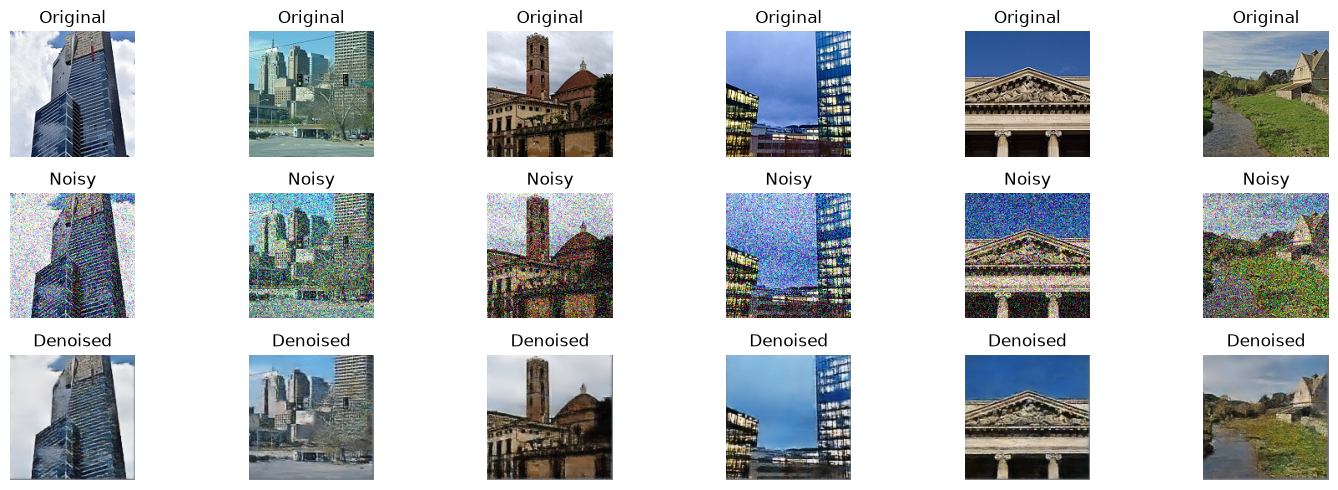

In [115]:
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    dataiter = iter(test_dataloader)
    images, _ = next(dataiter)
    images = images.to(DEVICE)

    noisy_images = images + NOISE_FACTOR * torch.randn_like(images)
    noisy_images = torch.clamp(noisy_images, 0., 1.)

    outputs = model(noisy_images)

    images = images.cpu().numpy()
    noisy_images = noisy_images.cpu().numpy()
    outputs = outputs.cpu().numpy()

    fig, axes = plt.subplots(nrows=3, ncols=len(images), figsize=(15, 5))
    for i in range(len(images)):
        axes[0, i].imshow(images[i].transpose(1, 2, 0))
        axes[0, i].axis('off')
        axes[0, i].set_title('Original')

        axes[1, i].imshow(noisy_images[i].transpose(1, 2, 0))
        axes[1, i].axis('off')
        axes[1, i].set_title('Noisy')

        axes[2, i].imshow(outputs[i].transpose(1, 2, 0))
        axes[2, i].axis('off')
        axes[2, i].set_title('Denoised')

plt.tight_layout()
plt.show()